## Selected Research Question:
"Do genes responsible for first-pass drug metabolism (such as CYP enzymes) show
significantly lower expression in cirrhotic livers compared to healthy livers?"
## Project Objectives:
1. To acquire and preprocess a public gene expression dataset comparing healthy and
cirrhotic human livers from NCBI GEO.
2. To explore and visualize the data by comparing the expression levels of key
drug-metabolizing genes (such as CYP3A4) across healthy and diseased samples.
3. To train and evaluate a machine learning classification model to predict liver tissue
states based on these metabolic gene profiles.
4. To interpret the results and conclude how liver cirrhosis impacts drug-metabolizing
gene expression and first-pass metabolic capacity.

In [1]:
! pip install GEOparse pydeseq2 pandas numpy matplotlib seaborn

In [2]:
import os; print(os.getcwd())

/content


## DATA ACQUSITION

In [3]:
import GEOparse
import pandas as pd
import numpy as np
from pydeseq2.ds import DeseqDataSet, DeseqStats

def inspect_geo_series(accession_id):
    print(f"\n--- Inspecting {accession_id} ---")
    gse = GEOparse.get_GEO(geo=accession_id, destdir="./geodata", annotate_gpl=True)
    platforms = list(gse.gpl.keys()) if hasattr(gse, 'gpl') else "Unknown"
    print(f"Platform(s) (GPL): {platforms}")
    print(f"Total samples:{len(gse.gsms)}")

    meta_list = []
    for gsm_name, gsm in  gse.gsms.items():
        source = gsm.metadata.get("source_name_ch1",[ "Unknown"])[0]
        title = gsm.metadata.get("title",['Unknown'])[0]
        meta_list.append({'sample':gsm_name, 'title':title, 'source':source})
    meta_df = pd.DataFrame(meta_list)
    meta_df['predicted_group'] = meta_df['source'].apply(
        lambda x:'cirrhosis' if any(term in x.lower() for term in ['cirrhosis', 'cirrhotic', 'fibrosis'])
        else ('healthy' if any(term in x.lower() for term in ['normal', 'healthy', 'control']) else 'unclassified')

    )
    print ("Group Breakdown Preview:")
    print (meta_df['predicted_group'].value_counts())
    return gse, meta_df



/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [4]:
gse_candidate, meta_candidate = inspect_geo_series("GSE25097")
unclassified_df = meta_candidate[meta_candidate['predicted_group'] == 'unclassified']
print(unclassified_df['source'].value_counts())

09-Nov-2026 07:59:59 DEBUG utils - Directory ./geodata already exists. Skipping.
DEBUG:GEOparse:Directory ./geodata already exists. Skipping.
09-Nov-2026 07:59:59 INFO GEOparse - File already exist: using local version.
INFO:GEOparse:File already exist: using local version.
09-Nov-2026 07:59:59 INFO GEOparse - Parsing ./geodata/GSE25097_family.soft.gz: 
INFO:GEOparse:Parsing ./geodata/GSE25097_family.soft.gz: 
09-Nov-2026 07:59:59 DEBUG GEOparse - DATABASE: GeoMiame
DEBUG:GEOparse:DATABASE: GeoMiame
09-Nov-2026 07:59:59 DEBUG GEOparse - SERIES: GSE25097
DEBUG:GEOparse:SERIES: GSE25097
09-Nov-2026 07:59:59 DEBUG GEOparse - PLATFORM: GPL10687
DEBUG:GEOparse:PLATFORM: GPL10687
09-Nov-2026 07:59:59 DEBUG GEOparse - SAMPLE: GSM616704
DEBUG:GEOparse:SAMPLE: GSM616704
09-Nov-2026 07:59:59 DEBUG GEOparse - SAMPLE: GSM616705
DEBUG:GEOparse:SAMPLE: GSM616705



--- Inspecting GSE25097 ---


09-Nov-2026 07:59:59 DEBUG GEOparse - SAMPLE: GSM616706
DEBUG:GEOparse:SAMPLE: GSM616706
09-Nov-2026 07:59:59 DEBUG GEOparse - SAMPLE: GSM616707
DEBUG:GEOparse:SAMPLE: GSM616707
09-Nov-2026 07:59:59 DEBUG GEOparse - SAMPLE: GSM616708
DEBUG:GEOparse:SAMPLE: GSM616708
09-Nov-2026 08:00:00 DEBUG GEOparse - SAMPLE: GSM616709
DEBUG:GEOparse:SAMPLE: GSM616709
09-Nov-2026 08:00:00 DEBUG GEOparse - SAMPLE: GSM616710
DEBUG:GEOparse:SAMPLE: GSM616710
09-Nov-2026 08:00:00 DEBUG GEOparse - SAMPLE: GSM616711
DEBUG:GEOparse:SAMPLE: GSM616711
09-Nov-2026 08:00:00 DEBUG GEOparse - SAMPLE: GSM616712
DEBUG:GEOparse:SAMPLE: GSM616712
09-Nov-2026 08:00:00 DEBUG GEOparse - SAMPLE: GSM616713
DEBUG:GEOparse:SAMPLE: GSM616713
09-Nov-2026 08:00:00 DEBUG GEOparse - SAMPLE: GSM616714
DEBUG:GEOparse:SAMPLE: GSM616714
09-Nov-2026 08:00:00 DEBUG GEOparse - SAMPLE: GSM616715
DEBUG:GEOparse:SAMPLE: GSM616715
09-Nov-2026 08:00:00 DEBUG GEOparse - SAMPLE: GSM616716
DEBUG:GEOparse:SAMPLE: GSM616716
09-Nov-2026 08:00:00 

Platform(s) (GPL): Unknown
Total samples:557
Group Breakdown Preview:
predicted_group
unclassified    511
cirrhosis        40
healthy           6
Name: count, dtype: int64
source
tumor        268
non_tumor    243
Name: count, dtype: int64


FROM GSE25097: Total samples:557
Group Breakdown Preview:
predicted_group
unclassified    511
cirrhosis        40
healthy           6
Name: count, dtype: int64
source
tumor        268
non_tumor    243
Name: count, dtype: int64

In [5]:
gse_candidate, meta_candidate = inspect_geo_series("GSE14323")
unclassified_df = meta_candidate[meta_candidate['predicted_group'] == 'unclassified']
print(unclassified_df['source'].value_counts())

09-Nov-2026 08:00:51 DEBUG utils - Directory ./geodata already exists. Skipping.
DEBUG:GEOparse:Directory ./geodata already exists. Skipping.
09-Nov-2026 08:00:51 INFO GEOparse - Downloading ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE14nnn/GSE14323/soft/GSE14323_family.soft.gz to ./geodata/GSE14323_family.soft.gz
INFO:GEOparse:Downloading ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE14nnn/GSE14323/soft/GSE14323_family.soft.gz to ./geodata/GSE14323_family.soft.gz



--- Inspecting GSE14323 ---


100%|██████████| 34.6M/34.6M [00:00<00:00, 58.5MB/s]
09-Nov-2026 08:00:52 DEBUG downloader - Size validation passed
DEBUG:GEOparse:Size validation passed
09-Nov-2026 08:00:52 DEBUG downloader - Moving /tmp/tmpr1f_usz_ to /content/geodata/GSE14323_family.soft.gz
DEBUG:GEOparse:Moving /tmp/tmpr1f_usz_ to /content/geodata/GSE14323_family.soft.gz
09-Nov-2026 08:00:52 DEBUG downloader - Successfully downloaded ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE14nnn/GSE14323/soft/GSE14323_family.soft.gz
DEBUG:GEOparse:Successfully downloaded ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE14nnn/GSE14323/soft/GSE14323_family.soft.gz
09-Nov-2026 08:00:52 INFO GEOparse - Parsing ./geodata/GSE14323_family.soft.gz: 
INFO:GEOparse:Parsing ./geodata/GSE14323_family.soft.gz: 
09-Nov-2026 08:00:52 DEBUG GEOparse - DATABASE: GeoMiame
DEBUG:GEOparse:DATABASE: GeoMiame
09-Nov-2026 08:00:52 DEBUG GEOparse - SERIES: GSE14323
DEBUG:GEOparse:SERIES: GSE14323
09-Nov-2026 08:00:52 DEBUG GEOparse - PLATFORM: GPL96
DEBUG:GEOpa

Platform(s) (GPL): Unknown
Total samples:124
Group Breakdown Preview:
predicted_group
cirrhosis       58
unclassified    47
healthy         19
Name: count, dtype: int64
source
liver tissue with HCC    47
Name: count, dtype: int64


FROM GSE14323 Platform(s) (GPL): Unknown
Total samples:124
Group Breakdown Preview:
predicted_group
cirrhosis       58
unclassified    47
healthy         19
Name: count, dtype: int64
source
liver tissue with HCC    47
Name: count, dtype: int64

In [6]:
gse_candidate, meta_candidate = inspect_geo_series("GSE6764")
unclassified_df = meta_candidate[meta_candidate['predicted_group'] == 'unclassified']
print(unclassified_df['source'].value_counts())

09-Nov-2026 08:01:17 DEBUG utils - Directory ./geodata already exists. Skipping.
DEBUG:GEOparse:Directory ./geodata already exists. Skipping.
09-Nov-2026 08:01:17 INFO GEOparse - Downloading ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE6nnn/GSE6764/soft/GSE6764_family.soft.gz to ./geodata/GSE6764_family.soft.gz
INFO:GEOparse:Downloading ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE6nnn/GSE6764/soft/GSE6764_family.soft.gz to ./geodata/GSE6764_family.soft.gz



--- Inspecting GSE6764 ---


100%|██████████| 36.9M/36.9M [00:00<00:00, 66.7MB/s]
09-Nov-2026 08:01:18 DEBUG downloader - Size validation passed
DEBUG:GEOparse:Size validation passed
09-Nov-2026 08:01:18 DEBUG downloader - Moving /tmp/tmp57qzwbso to /content/geodata/GSE6764_family.soft.gz
DEBUG:GEOparse:Moving /tmp/tmp57qzwbso to /content/geodata/GSE6764_family.soft.gz
09-Nov-2026 08:01:18 DEBUG downloader - Successfully downloaded ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE6nnn/GSE6764/soft/GSE6764_family.soft.gz
DEBUG:GEOparse:Successfully downloaded ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE6nnn/GSE6764/soft/GSE6764_family.soft.gz
09-Nov-2026 08:01:18 INFO GEOparse - Parsing ./geodata/GSE6764_family.soft.gz: 
INFO:GEOparse:Parsing ./geodata/GSE6764_family.soft.gz: 
09-Nov-2026 08:01:18 DEBUG GEOparse - DATABASE: GeoMiame
DEBUG:GEOparse:DATABASE: GeoMiame
09-Nov-2026 08:01:18 DEBUG GEOparse - SERIES: GSE6764
DEBUG:GEOparse:SERIES: GSE6764
09-Nov-2026 08:01:18 DEBUG GEOparse - PLATFORM: GPL570
DEBUG:GEOparse:PLATFOR

Platform(s) (GPL): Unknown
Total samples:75
Group Breakdown Preview:
predicted_group
unclassified    52
cirrhosis       13
healthy         10
Name: count, dtype: int64
source
human liver; low-grade dysplastic liver tissue     10
human liver; very advanced HCC                     10
human liver; early HCC                             10
human liver; very early HCC                         8
human liver; high-grade dysplastic liver tissue     7
human liver; advanced HCC                           7
Name: count, dtype: int64


FROM GSE6764 Platform(s) (GPL): Unknown
Total samples:75
Group Breakdown Preview:
predicted_group
unclassified    52
cirrhosis       13
healthy         10
Name: count, dtype: int64
source
human liver; low-grade dysplastic liver tissue     10
human liver; very advanced HCC                     10
human liver; early HCC                             10
human liver; very early HCC                         8
human liver; high-grade dysplastic liver tissue     7
human liver; advanced HCC                           7
Name: count, dtype: int64

In [7]:
gse_139602, meta_139602 = inspect_geo_series("GSE139602")
unclassified_df = meta_139602[meta_139602['predicted_group'] == 'unclassified']
print(unclassified_df['source'].value_counts())


09-Nov-2026 08:01:38 DEBUG utils - Directory ./geodata already exists. Skipping.
DEBUG:GEOparse:Directory ./geodata already exists. Skipping.
09-Nov-2026 08:01:38 INFO GEOparse - Downloading ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE139nnn/GSE139602/soft/GSE139602_family.soft.gz to ./geodata/GSE139602_family.soft.gz
INFO:GEOparse:Downloading ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE139nnn/GSE139602/soft/GSE139602_family.soft.gz to ./geodata/GSE139602_family.soft.gz



--- Inspecting GSE139602 ---


100%|██████████| 37.7M/37.7M [00:00<00:00, 47.2MB/s]
09-Nov-2026 08:01:39 DEBUG downloader - Size validation passed
DEBUG:GEOparse:Size validation passed
09-Nov-2026 08:01:39 DEBUG downloader - Moving /tmp/tmp5wts7tmi to /content/geodata/GSE139602_family.soft.gz
DEBUG:GEOparse:Moving /tmp/tmp5wts7tmi to /content/geodata/GSE139602_family.soft.gz
09-Nov-2026 08:01:39 DEBUG downloader - Successfully downloaded ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE139nnn/GSE139602/soft/GSE139602_family.soft.gz
DEBUG:GEOparse:Successfully downloaded ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE139nnn/GSE139602/soft/GSE139602_family.soft.gz
09-Nov-2026 08:01:39 INFO GEOparse - Parsing ./geodata/GSE139602_family.soft.gz: 
INFO:GEOparse:Parsing ./geodata/GSE139602_family.soft.gz: 
09-Nov-2026 08:01:39 DEBUG GEOparse - DATABASE: GeoMiame
DEBUG:GEOparse:DATABASE: GeoMiame
09-Nov-2026 08:01:39 DEBUG GEOparse - SERIES: GSE139602
DEBUG:GEOparse:SERIES: GSE139602
09-Nov-2026 08:01:39 DEBUG GEOparse - PLATFORM: GPL13

Platform(s) (GPL): Unknown
Total samples:39
Group Breakdown Preview:
predicted_group
unclassified    39
Name: count, dtype: int64
source
Liver Biopsy    39
Name: count, dtype: int64


FROM GSE139602
Total samples:39
Group Breakdown Preview:
predicted_group
unclassified    39
Name: count, dtype: int64
source
Liver Biopsy    39
Name: count, dtype: int64






In [8]:
# Inspect all available metadata keys and sample titles for GSE139602
meta_details = []
for gsm_name, gsm in gse_139602.gsms.items():
    title = gsm.metadata.get('title', [''])[0]
    characteristics = gsm.metadata.get('characteristics_ch1', [])
    meta_details.append({'sample': gsm_name, 'title': title, 'char': str(characteristics)})

details_df = pd.DataFrame(meta_details)
print(details_df.head(10))

       sample                        title                        char
0  GSM4144550  Healthy Liver biopsy (LMS1)  ['disease state: Healthy']
1  GSM4144551  Healthy Liver biopsy (LMS2)  ['disease state: Healthy']
2  GSM4144552  Healthy Liver biopsy (LMS3)  ['disease state: Healthy']
3  GSM4144553  Healthy Liver biopsy (LMS4)  ['disease state: Healthy']
4  GSM4144554  Healthy Liver biopsy (LMS5)  ['disease state: Healthy']
5  GSM4144555  Healthy Liver biopsy (LMS6)  ['disease state: Healthy']
6  GSM4144556    eCLD Liver biopsy (LM039)     ['disease state: eCLD']
7  GSM4144557    eCLD Liver biopsy (LM040)     ['disease state: eCLD']
8  GSM4144558    eCLD Liver biopsy (LM118)     ['disease state: eCLD']
9  GSM4144559    eCLD Liver biopsy (LM071)     ['disease state: eCLD']


### GEO Candidate Dataset Evaluation Summary

| GEO Accession | Platform | Total Samples | Healthy Controls ($n$) | Cirrhosis Samples ($n$) | Confounding Groups / Exclusions | Meets $\ge 15$ Per Group Rule? | Verdict |
| :--- | :--- | :---: | :---: | :---: | :--- | :---: | :--- |
| **GSE14323** | GPL570 | 124 | **19** | **58** | 47 liver tissues with HCC (can be filtered) | **Yes** | **Selected** — Best sample balance & clear non-tumor subset. |
| **GSE139602** | GPL13667 | 39 | 6 | 20 | 5 eCLD, 8 ACLF; progressive disease staging | **No** | *Underpowered* — Healthy control group ($n=6$) is too small. |
| **GSE25097** | GPL10687 | 557 | 6 | 40 | 268 tumor, 243 non-tumor | **No** | *Underpowered* — Healthy control group ($n=6$) is too small. |
| **GSE6764** | GPL570 | 75 | 10 | 13 | 52 dysplasia / HCC stages | **No** | *Underpowered* — Neither group reaches $n=15$. |

## **GSE14323 Selected** - Best sample balance & clear non-tumor subset.

## Data Preprocessing and Quality Control

In [9]:
gse = GEOparse.get_GEO(geo="GSE14323", destdir="./geodata", annotate_gpl=True)

09-Nov-2026 08:02:30 DEBUG utils - Directory ./geodata already exists. Skipping.
DEBUG:GEOparse:Directory ./geodata already exists. Skipping.
09-Nov-2026 08:02:30 INFO GEOparse - File already exist: using local version.
INFO:GEOparse:File already exist: using local version.
09-Nov-2026 08:02:30 INFO GEOparse - Parsing ./geodata/GSE14323_family.soft.gz: 
INFO:GEOparse:Parsing ./geodata/GSE14323_family.soft.gz: 
09-Nov-2026 08:02:30 DEBUG GEOparse - DATABASE: GeoMiame
DEBUG:GEOparse:DATABASE: GeoMiame
09-Nov-2026 08:02:30 DEBUG GEOparse - SERIES: GSE14323
DEBUG:GEOparse:SERIES: GSE14323
09-Nov-2026 08:02:30 DEBUG GEOparse - PLATFORM: GPL96
DEBUG:GEOparse:PLATFORM: GPL96
09-Nov-2026 08:02:31 DEBUG GEOparse - PLATFORM: GPL571
DEBUG:GEOparse:PLATFORM: GPL571
09-Nov-2026 08:02:31 DEBUG GEOparse - SAMPLE: GSM358103
DEBUG:GEOparse:SAMPLE: GSM358103
09-Nov-2026 08:02:31 DEBUG GEOparse - SAMPLE: GSM358104
DEBUG:GEOparse:SAMPLE: GSM358104
09-Nov-2026 08:02:31 DEBUG GEOparse - SAMPLE: GSM358105
DE

In [10]:
## initial samples
initial_samples = len(gse.gsms)
print(f"Total samples: {initial_samples}")

Total samples: 124


In [11]:
expression_frames =[]
meta_list = []

for gsm_name, gsm in gse.gsms.items():
    source = gsm.metadata.get("source_name_ch1",[ ''])[0]
    # filtering out the 47 GCC tissue samples, keeping only healthy and cirrhosis samples
    if 'hcc' in source.lower():
        continue
    group = 'healthy' if any(term in source.lower() for term in ['normal', 'healthy', 'control']) else 'cirrhosis'
    meta_list.append({'sample':gsm_name, 'source':source, 'group':group})
    df = gsm.table.set_index('ID_REF')['VALUE']
    expression_frames.append(df)

meta_df = pd.DataFrame(meta_list).set_index('sample')
expression_matrix = pd.concat(expression_frames, axis=1)
initial_probes = expression_matrix.shape[0]
print(f"Total probes before filtering: {initial_probes}")
print(f"Retained samples after filtering: {len(meta_df)} (Healthy:{sum(meta_df['group']=='healthy')}, Cirrhosis:{sum(meta_df['group']=='cirrhosis')})")




Total probes before filtering: 22277
Retained samples after filtering: 60 (Healthy:19, Cirrhosis:41)


In [12]:
# Normalization and Transformation check
min_val, max_val = expression_matrix.min().min(), expression_matrix.max().max()
print(f"Expression value range: [{min_val:.2f}, {max_val:.2f}]")
if max_val > 50:
    # values are not log-transformed therefore log-transform
    expression_matrix = np.log2(expression_matrix + 1)
    print("Applying log2 transformation to expression values.")
else:
    print("Expression values are already log-transformed.")

Expression value range: [3.48, 14.36]
Expression values are already log-transformed.


In [13]:
# handling missing values and low-expression filtering

expression_matrix = expression_matrix.dropna()
variance_threshold = expression_matrix.var(axis=1).quantile(0.10) # drop bottom 10% lowest variance genes
expression_matrix = expression_matrix[expression_matrix.var(axis=1) > variance_threshold]
print(f" Remaining genes: {expression_matrix.shape[0]}")

 Remaining genes: 20049


In [14]:
print(expression_matrix.shape)

(20049, 60)


reduced feature space from 22,277 down to 20,049 genes

## 4. Exploratory Data Analysis
**Goal:** describe and visualise GSE14323 (healthy vs cirrhotic liver) before any statistical testing.
**Questions:** Are the data clean? Do the groups differ overall? Do drug-metabolism genes look lower in cirrhosis? Are there outliers or batch effects?

In [15]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
EDA_PAL = {"healthy": "#2a9d8f", "cirrhosis": "#e76f51"}
EDA_FIG = (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()) / "figures"
EDA_FIG.mkdir(exist_ok=True)

# --- work on COPIES: Stage 3's variables stay untouched ---
eda_meta = meta_df.copy()
eda_raw = expression_matrix.copy()

# --- label columns by sample id (Stage 3 left every column named 'VALUE') ---
print("Distinct column labels in Stage 3 matrix:", eda_raw.columns.unique().tolist()[:3])
assert eda_raw.shape[1] == eda_meta.shape[0], "sample count mismatch between matrix and metadata"
if set(eda_raw.columns) == set(eda_meta.index):   # already fixed upstream
    eda_raw = eda_raw[eda_meta.index]
else:                                             # same loop built both -> same order
    eda_raw.columns = eda_meta.index

eda_meta["platform"] = [gse.gsms[s].metadata["platform_id"][0] for s in eda_meta.index]

# --- diagnostic 1: what are ALL 124 samples called, and where did the 17 go? ---
eda_all = pd.DataFrame({
    gid: {"source": gsm.metadata["source_name_ch1"][0],
          "platform": gsm.metadata["platform_id"][0]}
    for gid, gsm in gse.gsms.items()
}).T
print("\nAll 124 samples by label and platform:")
print(eda_all.groupby(["source", "platform"]).size())

# --- diagnostic 2: what we kept ---
print("\nKept:", eda_meta["group"].value_counts().to_dict(), "(minutes say healthy 19, cirrhosis 58)")
print(pd.crosstab(eda_meta["group"], eda_meta["platform"]))

Distinct column labels in Stage 3 matrix: ['VALUE']

All 124 samples by label and platform:
source                          platform
Normal liver tissue             GPL571      19
liver tissue with HCC           GPL571      38
                                GPL96        9
liver tissue with cirrhosis     GPL571      41
liver tissue with cirrhosisHCC  GPL571      17
dtype: int64

Kept: {'cirrhosis': 41, 'healthy': 19} (minutes say healthy 19, cirrhosis 58)
platform   GPL571
group            
cirrhosis      41
healthy        19


In [16]:
eda_platforms = eda_meta["platform"].unique()
eda_ann = pd.concat([gse.gpls[p].table for p in eda_platforms]).drop_duplicates("ID")
print(eda_ann.columns.tolist())      # find the gene-symbol column

eda_symcol = next(c for c in eda_ann.columns if c.lower().replace(" ", "") in ("genesymbol", "symbol"))
eda_p2g = eda_ann.set_index("ID")[eda_symcol].astype(str).str.split("///").str[0].str.strip()

eda_tmp = eda_raw.copy()
eda_tmp["gene"] = eda_p2g.reindex(eda_tmp.index).values
n_before = eda_tmp.shape[0]
eda_tmp = eda_tmp[eda_tmp["gene"].notna() & ~eda_tmp["gene"].isin(["", "nan", "---"])]
print(f"Probes with a gene symbol: {eda_tmp.shape[0]} of {n_before}")

# several probes per gene -> keep the probe with the highest mean expression
eda_tmp["_m"] = eda_tmp.drop(columns="gene").mean(axis=1)
eda_expr = (eda_tmp.sort_values("_m", ascending=False)
                   .drop_duplicates("gene")
                   .drop(columns="_m")
                   .set_index("gene"))
print("Unique genes:", eda_expr.shape[0])

# order samples: healthy first, then cirrhosis
eda_order = eda_meta["group"].map({"healthy": 0, "cirrhosis": 1}).sort_values(kind="stable").index
eda_expr = eda_expr[eda_order]
eda_meta = eda_meta.loc[eda_order]

['ID', 'GB_ACC', 'SPOT_ID', 'Species Scientific Name', 'Annotation Date', 'Sequence Type', 'Sequence Source', 'Target Description', 'Representative Public ID', 'Gene Title', 'Gene Symbol', 'ENTREZ_GENE_ID', 'RefSeq Transcript ID', 'Gene Ontology Biological Process', 'Gene Ontology Cellular Component', 'Gene Ontology Molecular Function']
Probes with a gene symbol: 19328 of 20049
Unique genes: 12316


In [17]:
eda_panel = ["CYP3A4","CYP3A5","CYP2C9","CYP2C19","CYP2D6","CYP1A2","CYP2E1",
             "UGT1A1","UGT2B7","GSTA1","SULT1A1","SULT1A2","SULT1E1","SULT2A1",
             "ABCB1","SLCO1B1","SLC22A1"]
eda_found   = [g for g in eda_panel if g in eda_expr.index]
eda_missing = [g for g in eda_panel if g not in eda_expr.index]
print("On the chip:", eda_found)
print("NOT on the chip (report this):", eda_missing)

On the chip: ['CYP3A4', 'CYP3A5', 'CYP2C9', 'CYP2C19', 'CYP2D6', 'CYP1A2', 'CYP2E1', 'UGT1A1', 'GSTA1', 'SULT1A1', 'SULT1A2', 'SULT1E1', 'SULT2A1', 'ABCB1', 'SLCO1B1', 'SLC22A1']
NOT on the chip (report this): ['UGT2B7']


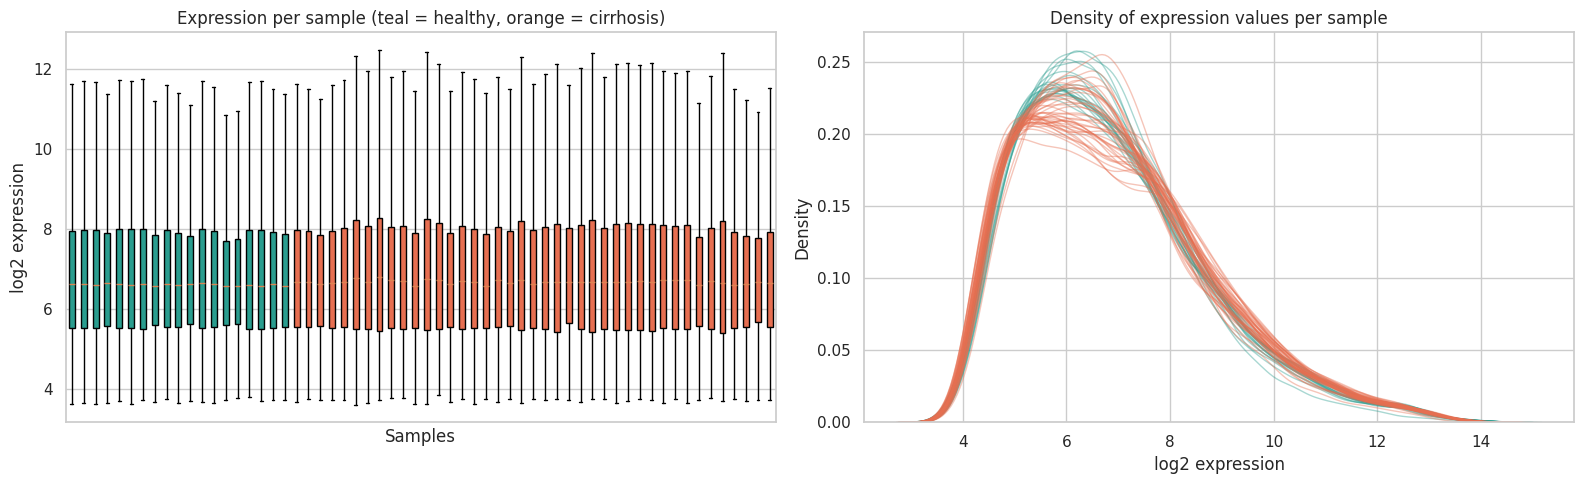

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

bp = axes[0].boxplot([eda_expr[s] for s in eda_order], patch_artist=True, showfliers=False)
for patch, s in zip(bp["boxes"], eda_order):
    patch.set_facecolor(EDA_PAL[eda_meta.loc[s, "group"]])
axes[0].set_title("Expression per sample (teal = healthy, orange = cirrhosis)")
axes[0].set_xlabel("Samples"); axes[0].set_ylabel("log2 expression"); axes[0].set_xticks([])

for s in eda_order:
    sns.kdeplot(eda_expr[s], ax=axes[1], color=EDA_PAL[eda_meta.loc[s, "group"]], alpha=0.4, linewidth=1)
axes[1].set_title("Density of expression values per sample"); axes[1].set_xlabel("log2 expression")

plt.tight_layout(); plt.savefig(EDA_FIG / "eda1_distributions.png", dpi=150); plt.show()

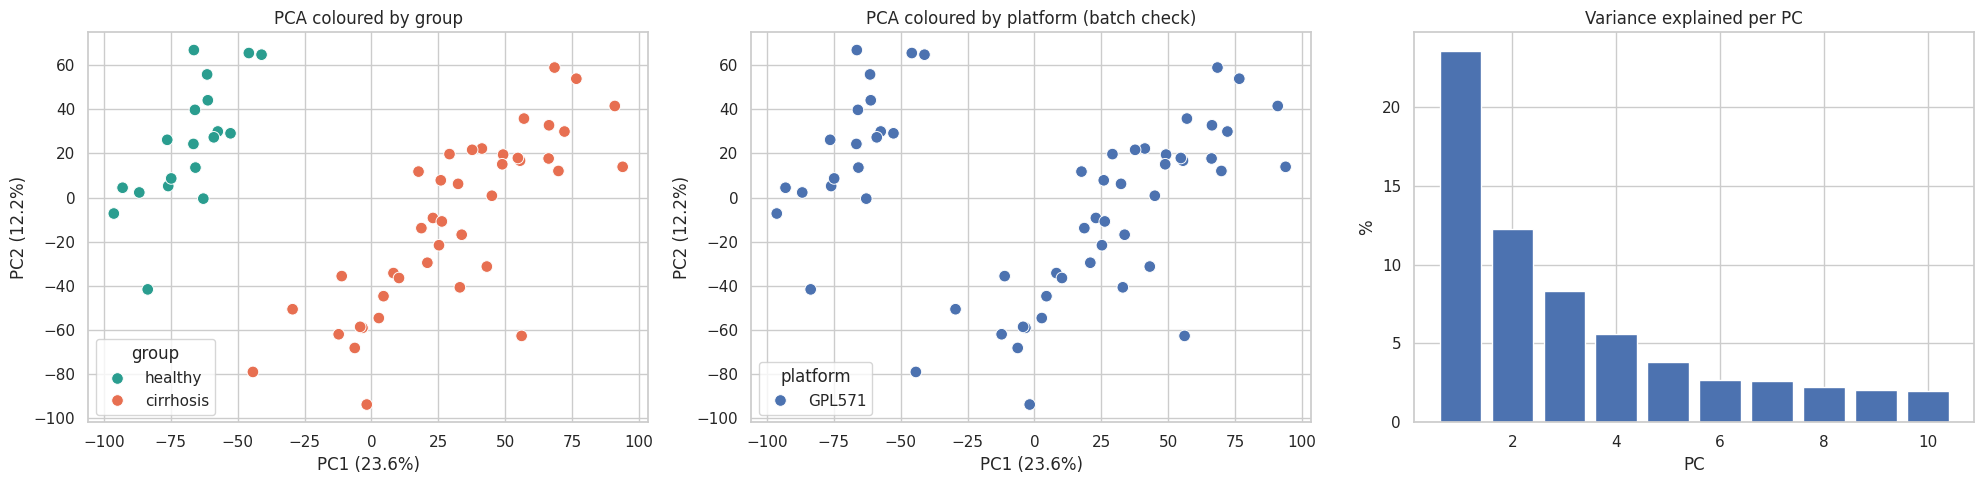

Possible outliers (>3 SD on PC1/PC2): none


In [19]:
eda_X = StandardScaler().fit_transform(eda_expr.T.values)      # samples x genes, each gene standardised
eda_pca = PCA(n_components=10, random_state=0)
eda_pcs = eda_pca.fit_transform(eda_X)
eda_pc = pd.DataFrame(eda_pcs[:, :2], index=eda_order, columns=["PC1", "PC2"]).join(eda_meta)
eda_ev = eda_pca.explained_variance_ratio_ * 100

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
sns.scatterplot(data=eda_pc, x="PC1", y="PC2", hue="group", palette=EDA_PAL, s=70, ax=axes[0])
axes[0].set_xlabel(f"PC1 ({eda_ev[0]:.1f}%)"); axes[0].set_ylabel(f"PC2 ({eda_ev[1]:.1f}%)")
axes[0].set_title("PCA coloured by group")

sns.scatterplot(data=eda_pc, x="PC1", y="PC2", hue="platform", s=70, ax=axes[1])
axes[1].set_xlabel(f"PC1 ({eda_ev[0]:.1f}%)"); axes[1].set_ylabel(f"PC2 ({eda_ev[1]:.1f}%)")
axes[1].set_title("PCA coloured by platform (batch check)")

axes[2].bar(range(1, 11), eda_ev); axes[2].set_title("Variance explained per PC")
axes[2].set_xlabel("PC"); axes[2].set_ylabel("%")

plt.tight_layout(); plt.savefig(EDA_FIG / "eda2_pca.png", dpi=150); plt.show()

eda_z = (eda_pc[["PC1","PC2"]] - eda_pc[["PC1","PC2"]].mean()) / eda_pc[["PC1","PC2"]].std()
print("Possible outliers (>3 SD on PC1/PC2):", eda_z[(eda_z.abs() > 3).any(axis=1)].index.tolist() or "none")

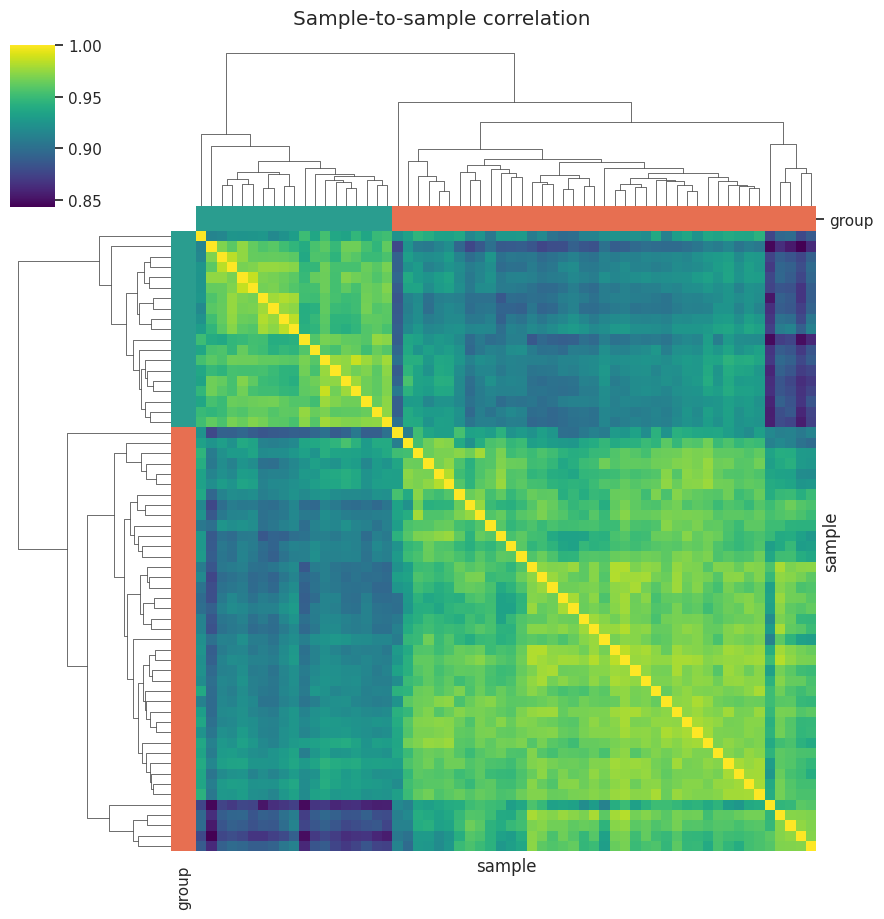

Lowest 5 average correlations:
 sample
GSM358211    0.910706
GSM358136    0.915012
GSM358206    0.915372
GSM358223    0.918713
GSM358224    0.920120
dtype: float64


In [20]:
eda_corr = eda_expr.corr()
eda_cc = eda_meta["group"].map(EDA_PAL)
eda_cg = sns.clustermap(eda_corr, cmap="viridis", col_colors=eda_cc, row_colors=eda_cc,
                        figsize=(9, 9), xticklabels=False, yticklabels=False)
eda_cg.fig.suptitle("Sample-to-sample correlation", y=1.02)
eda_cg.savefig(EDA_FIG / "eda3_sample_correlation.png", dpi=150)
plt.show()

eda_mean_corr = (eda_corr.sum() - 1) / (len(eda_corr) - 1)
print("Lowest 5 average correlations:\n", eda_mean_corr.sort_values().head(5))

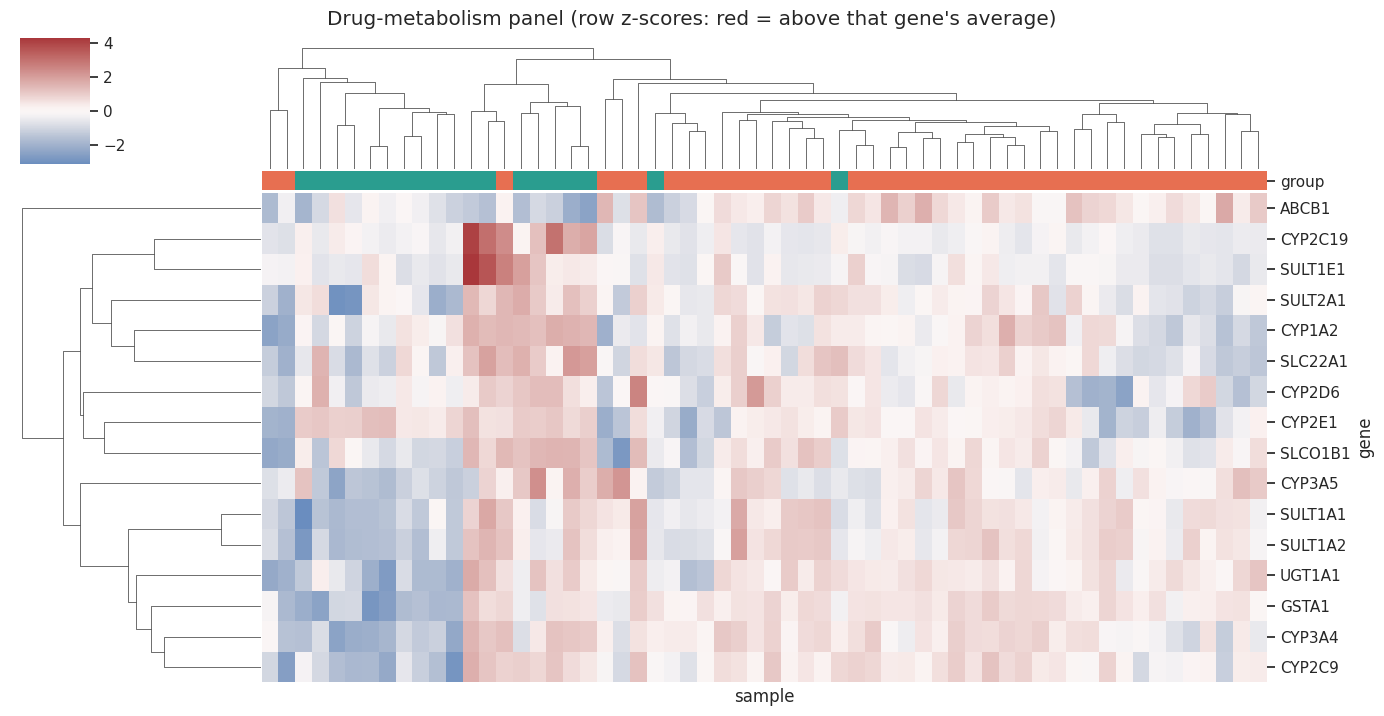

In [21]:
eda_hm = sns.clustermap(eda_expr.loc[eda_found], z_score=0, cmap="vlag", center=0,
                        col_colors=eda_meta["group"].map(EDA_PAL), col_cluster=True,
                        figsize=(14, 7), xticklabels=False)
eda_hm.fig.suptitle("Drug-metabolism panel (row z-scores: red = above that gene's average)", y=1.02)
eda_hm.savefig(EDA_FIG / "eda4_panel_heatmap.png", dpi=150)
plt.show()

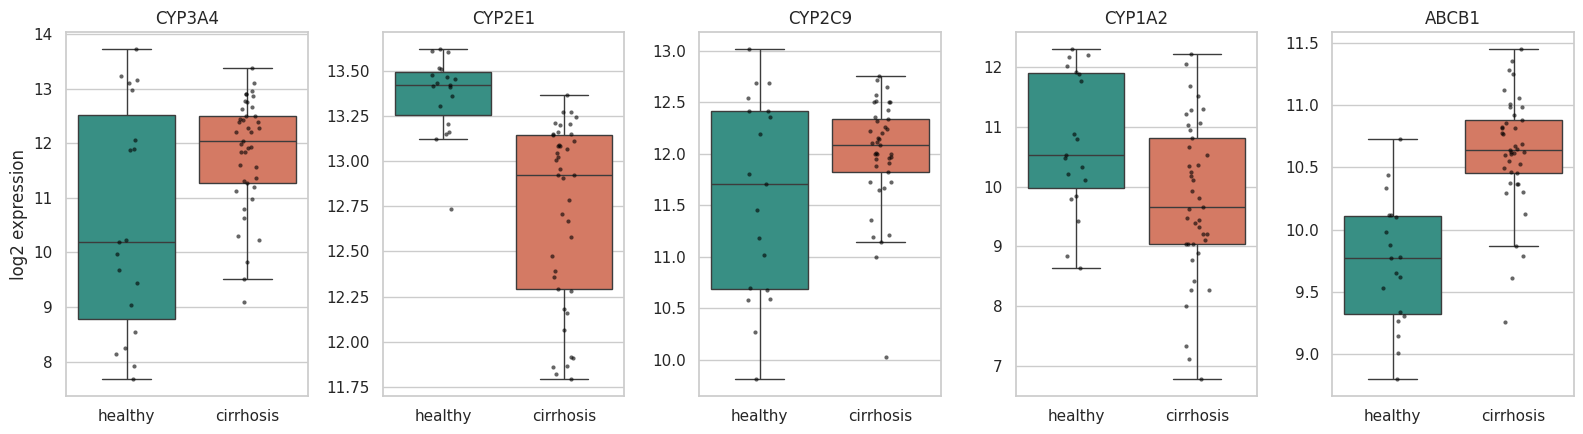

,mean_healthy,mean_cirrhosis,diff_log2 (cirr - healthy)
gene,,,
CYP2C19,7.08,5.45,-1.63
CYP1A2,10.74,9.77,-0.97
CYP2E1,13.37,12.72,-0.64
SLC22A1,10.76,10.18,-0.59
SULT1E1,4.79,4.33,-0.45
CYP2D6,9.83,9.49,-0.34
SLCO1B1,9.34,9.22,-0.12
SULT2A1,10.99,10.99,0.00
UGT1A1,11.37,11.70,0.33


In [22]:
eda_show = [g for g in ["CYP3A4","CYP2E1","CYP2C9","CYP1A2","UGT2B7","ABCB1"] if g in eda_expr.index]
eda_long = (eda_expr.loc[eda_show].T.join(eda_meta["group"])
            .melt(id_vars="group", var_name="gene", value_name="log2_expr"))

fig, axes = plt.subplots(1, len(eda_show), figsize=(3.2 * len(eda_show), 4.5))
axes = np.atleast_1d(axes)
for i, (ax, gname) in enumerate(zip(axes, eda_show)):
    d = eda_long[eda_long.gene == gname]
    sns.boxplot(data=d, x="group", y="log2_expr", hue="group", palette=EDA_PAL,
                order=["healthy", "cirrhosis"], showfliers=False, ax=ax, legend=False)
    sns.stripplot(data=d, x="group", y="log2_expr", order=["healthy", "cirrhosis"],
                  color="black", size=3, alpha=0.6, ax=ax)
    ax.set_title(gname); ax.set_xlabel("")
    ax.set_ylabel("log2 expression" if i == 0 else "")
plt.tight_layout(); plt.savefig(EDA_FIG / "eda5_panel_boxplots.png", dpi=150); plt.show()

# descriptive only: NO p-values (that is Stage 5)
eda_h = eda_meta.index[eda_meta.group == "healthy"]
eda_c = eda_meta.index[eda_meta.group == "cirrhosis"]
eda_tbl = pd.DataFrame({"mean_healthy": eda_expr.loc[eda_found, eda_h].mean(axis=1),
                        "mean_cirrhosis": eda_expr.loc[eda_found, eda_c].mean(axis=1)})
eda_tbl["diff_log2 (cirr - healthy)"] = eda_tbl["mean_cirrhosis"] - eda_tbl["mean_healthy"]
display(eda_tbl.round(2).sort_values("diff_log2 (cirr - healthy)"))

ALB: mean log2 = 9.24, higher than 89% of genes
APOA1: mean log2 = 13.21, higher than 100% of genes
CYP3A4: mean log2 = 11.43, higher than 98% of genes


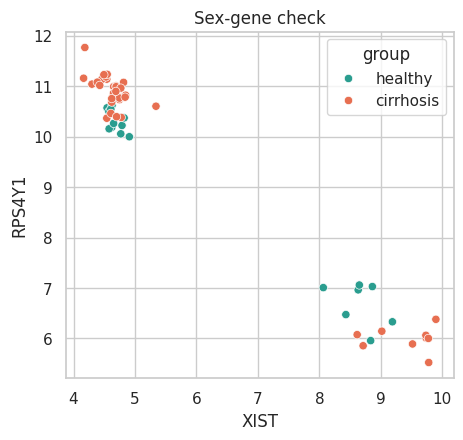

GSM358209 ['Tissue: Normal']
GSM358119 ['Tissue: cirrhosis']
group
cirrhosis    41
healthy      19
Name: count, dtype: int64


In [23]:
# 1) liver genes should rank among the most highly expressed
eda_mean = eda_expr.mean(axis=1)
eda_pct = eda_mean.rank(pct=True) * 100
for gname in ["ALB", "APOA1", "CYP3A4"]:
    if gname in eda_expr.index:
        print(f"{gname}: mean log2 = {eda_mean[gname]:.2f}, higher than {eda_pct[gname]:.0f}% of genes")

# 2) sex genes: XIST (female) vs RPS4Y1 (male) should form two clusters
if {"XIST", "RPS4Y1"} <= set(eda_expr.index):
    eda_sx = eda_expr.loc[["XIST", "RPS4Y1"]].T.join(eda_meta["group"])
    plt.figure(figsize=(5, 4.5))
    sns.scatterplot(data=eda_sx, x="XIST", y="RPS4Y1", hue="group", palette=EDA_PAL)
    plt.title("Sex-gene check")
    plt.savefig(EDA_FIG / "eda6_sex_check.png", dpi=150); plt.show()

# 3) any recorded sex/age/etiology to compare against?
for s in [eda_h[0], eda_c[0]]:
    print(s, gse.gsms[s].metadata.get("characteristics_ch1"))

# 4) group balance
print(eda_meta["group"].value_counts())

## EDA summary
- **Distributions:** All 60 samples have near-identical box and density shapes, so they are comparable. Cirrhosis boxes are slightly higher at the top end, but nothing is odd. The data was already log2 and normalized, so there is no before/after step.
- **PCA:** PC1 (23.6%) separates healthy from cirrhosis, with a few cirrhosis samples sitting between the groups. PC2 explains 12.2%. All samples are GPL571, so there is no chip batch effect, and no sample is more than 3 SD out.
- **Sample correlation:** Samples cluster by group. A small cluster of about 5 cirrhosis samples is the least similar to healthy ones, but average correlations are still above 0.91, so they are not outliers.
- **Panel heatmap:** The panel only partly separates the groups. Healthy samples form two blocks, and a few cirrhosis samples fall among them. Gene patterns are mixed, with no uniform downward shift.
- **Per-gene boxplots / table:** CYP2E1 (-0.64 log2) and CYP1A2 (-0.97) are lower in cirrhosis, and CYP2C19 is lowest (-1.63). CYP3A4 (+1.24), GSTA1 (+2.13), ABCB1 (+0.90) and CYP2C9 (+0.41) are higher, and the healthy group is very spread out for CYP3A4. Overall, 7 genes are lower, 1 is flat, and 8 are higher.
- **Sanity checks:** APOA1 (100th percentile), CYP3A4 (98th) and ALB (89th) are highly expressed, as expected for liver. XIST and RPS4Y1 split cleanly into male and female clusters. The sample labels carry no sex, age or etiology information.
- **Issues for later stages:** 41 cirrhosis samples, not 58 (see below); UGT2B7 is absent from the chip; groups are unbalanced (19 vs 41); the sex mix looks different between groups; and the cirrhosis genes that appear higher contradict our H1 and need careful testing.

## 5. Core Analysis: Differential Expression
**Goal:** test whether first-pass drug-metabolism genes differ between healthy (n=19) and cirrhotic (n=41) liver.
**Method:** Welch's two-sample t-test per gene on log2 expression (unequal variances, unequal group sizes),
Benjamini-Hochberg FDR across all genes. log2FC = mean(cirrhosis) − mean(healthy). Effect size = Hedges' g.
**Primary test:** two-sided (we do not assume direction). **Secondary:** one-sided test of H1 (lower in cirrhosis).
**Significance:** FDR < 0.05; |log2FC| ≥ 0.58 (1.5-fold) used for volcano colouring only.
PyDESeq2 is not used because the data are normalized microarray intensities, not RNA-seq counts.

In [24]:
from scipy import stats
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

ALPHA, LFC_T = 0.05, 0.58

de_expr = eda_expr.copy()                       # genes x samples, log2, one row per gene
h_ids = eda_meta.index[eda_meta.group == "healthy"]
c_ids = eda_meta.index[eda_meta.group == "cirrhosis"]

assert set(de_expr.columns) == set(eda_meta.index)
assert de_expr.isna().sum().sum() == 0
print(f"Genes tested: {de_expr.shape[0]} | healthy n={len(h_ids)} | cirrhosis n={len(c_ids)}")
print("Panel genes on chip:", eda_found)
print("Panel genes missing:", [g for g in eda_panel if g not in de_expr.index])

Genes tested: 12316 | healthy n=19 | cirrhosis n=41
Panel genes on chip: ['CYP3A4', 'CYP3A5', 'CYP2C9', 'CYP2C19', 'CYP2D6', 'CYP1A2', 'CYP2E1', 'UGT1A1', 'GSTA1', 'SULT1A1', 'SULT1A2', 'SULT1E1', 'SULT2A1', 'ABCB1', 'SLCO1B1', 'SLC22A1']
Panel genes missing: ['UGT2B7']


In [25]:
def run_de(expr, h_ids, c_ids):
    Xh, Xc = expr[h_ids].to_numpy(), expr[c_ids].to_numpy()
    nh, nc = Xh.shape[1], Xc.shape[1]
    t, p = stats.ttest_ind(Xc, Xh, axis=1, equal_var=False)

    mh, mc = Xh.mean(1), Xc.mean(1)
    vh, vc = Xh.var(1, ddof=1), Xc.var(1, ddof=1)
    lfc = mc - mh
    se = np.sqrt(vc / nc + vh / nh)
    dof = se**4 / ((vc / nc) ** 2 / (nc - 1) + (vh / nh) ** 2 / (nh - 1))   # Welch-Satterthwaite
    tcrit = stats.t.ppf(0.975, dof)

    sp = np.sqrt(((nc - 1) * vc + (nh - 1) * vh) / (nc + nh - 2))
    g = (lfc / sp) * (1 - 3 / (4 * (nc + nh) - 9))                         # Hedges' g

    res = pd.DataFrame({
        "mean_healthy": mh, "mean_cirrhosis": mc, "log2FC": lfc,
        "CI_low": lfc - tcrit * se, "CI_high": lfc + tcrit * se,
        "hedges_g": g, "t": t, "pvalue": p,
        "p_lower": stats.t.cdf(t, dof),            # one-sided: cirrhosis < healthy (H1)
    }, index=expr.index)
    res["pvalue"] = res["pvalue"].fillna(1.0)
    res["padj"] = stats.false_discovery_control(res["pvalue"].to_numpy(), method="bh")
    res["direction"] = np.where(res.padj >= ALPHA, "NS",
                         np.where(res.log2FC < 0, "Down in cirrhosis", "Up in cirrhosis"))
    return res

de_res = run_de(de_expr, h_ids, c_ids)

print(de_res.direction.value_counts())
print("Strong (FDR<0.05 & |log2FC|>=0.58):",
      ((de_res.padj < ALPHA) & (de_res.log2FC.abs() >= LFC_T)).sum())

direction
NS                   4471
Down in cirrhosis    4325
Up in cirrhosis      3520
Name: count, dtype: int64
Strong (FDR<0.05 & |log2FC|>=0.58): 2121


In [26]:
panel_res = de_res.loc[eda_found].copy()
panel_res["padj_panel_only"] = stats.false_discovery_control(panel_res.pvalue.to_numpy(), method="bh")
panel_res["padj_H1_lower"] = stats.false_discovery_control(panel_res.p_lower.to_numpy(), method="bh")

# non-parametric robustness check
panel_res["p_mannwhitney"] = [
    stats.mannwhitneyu(de_expr.loc[g, c_ids], de_expr.loc[g, h_ids], alternative="two-sided").pvalue
    for g in panel_res.index]

panel_res["supports_H1"] = (panel_res.log2FC < 0) & (panel_res.padj < ALPHA)
cols = ["mean_healthy","mean_cirrhosis","log2FC","CI_low","CI_high","hedges_g",
        "pvalue","padj","padj_H1_lower","p_mannwhitney","direction","supports_H1"]
panel_tbl = panel_res[cols].sort_values("log2FC")
display(panel_tbl.round(4))

print(panel_tbl.direction.value_counts())
print(f"H1 supported (significantly lower) in {panel_tbl.supports_H1.sum()} of {len(panel_tbl)} panel genes")

,mean_healthy,mean_cirrhosis,log2FC,CI_low,CI_high,hedges_g,pvalue,padj,padj_H1_lower,p_mannwhitney,direction,supports_H1
gene,,,,,,,,,,,,
CYP2C19,7.0809,5.4523,-1.6286,-2.6713,-0.5859,-1.1935,0.0039,0.0076,0.0156,0.0001,Down in cirrhosis,True
CYP1A2,10.7420,9.7721,-0.9699,-1.6517,-0.2882,-0.7530,0.0065,0.0120,0.0172,0.0144,Down in cirrhosis,True
CYP2E1,13.3687,12.7246,-0.6440,-0.8299,-0.4582,-1.4643,0.0000,0.0000,0.0000,0.0000,Down in cirrhosis,True
SLC22A1,10.7649,10.1795,-0.5853,-1.1795,0.0088,-0.6337,0.0532,0.0792,0.0852,0.0388,NS,False
SULT1E1,4.7876,4.3332,-0.4544,-0.9133,0.0044,-0.7241,0.0521,0.0776,0.0852,0.0453,NS,False
CYP2D6,9.8319,9.4889,-0.3431,-0.7272,0.0411,-0.4343,0.0788,0.1127,0.1051,0.1085,NS,False
SLCO1B1,9.3381,9.2163,-0.1219,-0.4963,0.2526,-0.1856,0.5125,0.5770,0.5857,0.6564,NS,False
SULT2A1,10.9889,10.9905,0.0016,-0.6092,0.6124,0.0018,0.9957,0.9967,1.0000,0.2870,NS,False
UGT1A1,11.3740,11.7047,0.3307,-0.0461,0.7075,0.5950,0.0827,0.1174,1.0000,0.1352,NS,False


direction
NS                   8
Up in cirrhosis      5
Down in cirrhosis    3
Name: count, dtype: int64
H1 supported (significantly lower) in 3 of 16 panel genes


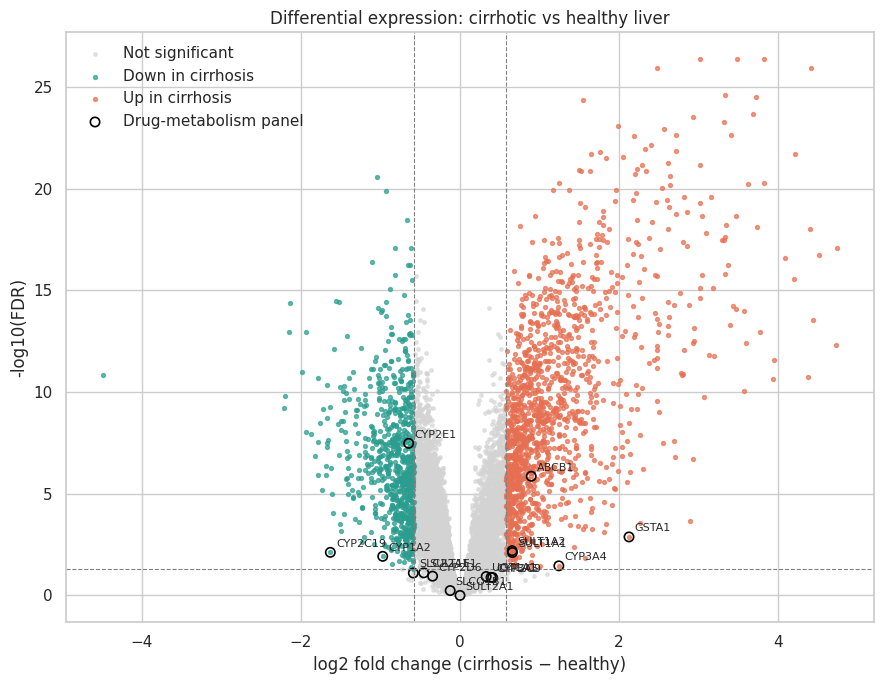

In [27]:
d = de_res.copy()
d["neglog10_padj"] = -np.log10(d.padj.clip(lower=1e-300))
sig = (d.padj < ALPHA) & (d.log2FC.abs() >= LFC_T)

fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(d.log2FC[~sig], d.neglog10_padj[~sig], s=6, c="lightgrey", alpha=0.6, label="Not significant")
ax.scatter(d.log2FC[sig & (d.log2FC < 0)], d.neglog10_padj[sig & (d.log2FC < 0)], s=8, c="#2a9d8f", alpha=0.7, label="Down in cirrhosis")
ax.scatter(d.log2FC[sig & (d.log2FC > 0)], d.neglog10_padj[sig & (d.log2FC > 0)], s=8, c="#e76f51", alpha=0.7, label="Up in cirrhosis")

pd_ = d.loc[eda_found]
ax.scatter(pd_.log2FC, pd_.neglog10_padj, s=45, facecolors="none", edgecolors="black", linewidths=1.2, label="Drug-metabolism panel")
for g, r in pd_.iterrows():
    ax.annotate(g, (r.log2FC, r.neglog10_padj), xytext=(4, 4), textcoords="offset points", fontsize=8)

ax.axhline(-np.log10(ALPHA), ls="--", c="grey", lw=0.8)
ax.axvline(-LFC_T, ls="--", c="grey", lw=0.8); ax.axvline(LFC_T, ls="--", c="grey", lw=0.8)
ax.set_xlabel("log2 fold change (cirrhosis − healthy)"); ax.set_ylabel("-log10(FDR)")
ax.set_title("Differential expression: cirrhotic vs healthy liver"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(EDA_FIG / "de1_volcano.png", dpi=150); plt.show()

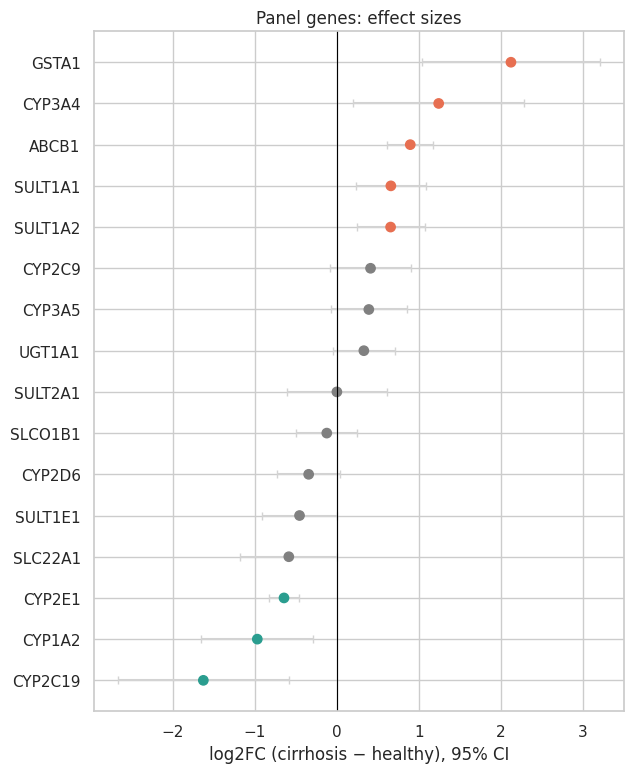

In [28]:
pt = panel_tbl.sort_values("log2FC")
fig, ax = plt.subplots(figsize=(6.5, 0.4 * len(pt) + 1.5))
colors = pt.direction.map({"Down in cirrhosis": "#2a9d8f", "Up in cirrhosis": "#e76f51", "NS": "grey"})
ax.errorbar(pt.log2FC, range(len(pt)), xerr=[pt.log2FC - pt.CI_low, pt.CI_high - pt.log2FC],
            fmt="none", ecolor="lightgrey", capsize=3, zorder=1)
ax.scatter(pt.log2FC, range(len(pt)), c=colors, s=45, zorder=2)
ax.axvline(0, c="black", lw=0.8)
ax.set_yticks(range(len(pt))); ax.set_yticklabels(pt.index)
ax.set_xlabel("log2FC (cirrhosis − healthy), 95% CI"); ax.set_title("Panel genes: effect sizes")
plt.tight_layout(); plt.savefig(EDA_FIG / "de2_panel_forest.png", dpi=150); plt.show()

In [29]:
probe_de = run_de(eda_raw, h_ids, c_ids)          # eda_raw is probe-level (all 60 samples)
probe_de["gene"] = eda_p2g.reindex(probe_de.index).values
look = probe_de[probe_de.gene.isin(["CYP3A4","CYP3A5","CYP2C19","GSTA1","CYP2C9"])]
display(look[["gene","mean_healthy","mean_cirrhosis","log2FC","padj"]].sort_values("gene").round(3))

,gene,mean_healthy,mean_cirrhosis,log2FC,padj
ID_REF,,,,,
216058_s_at,CYP2C19,7.081,5.452,-1.629,0.008
214419_s_at,CYP2C9,6.489,7.540,1.051,0.000
214420_s_at,CYP2C9,6.699,8.020,1.321,0.000
214421_x_at,CYP2C9,11.521,11.949,0.427,0.169
216025_x_at,CYP2C9,11.364,11.804,0.440,0.125
216661_x_at,CYP2C9,10.672,11.185,0.513,0.087
217558_at,CYP2C9,8.946,9.072,0.127,0.782
220017_x_at,CYP2C9,11.584,11.996,0.412,0.135
205998_x_at,CYP3A4,10.241,10.259,0.018,0.969


In [30]:
rows = {}
for gid, gsm in gse.gsms.items():
    src = gsm.metadata["source_name_ch1"][0]
    if gsm.metadata["platform_id"][0] == "GPL571" and src in ("Normal liver tissue",
            "liver tissue with cirrhosis", "liver tissue with cirrhosisHCC"):
        rows[gid] = "healthy" if src.startswith("Normal") else "cirrhosis"
grp58 = pd.Series(rows)

raw58 = pd.concat([gse.gsms[s].table.set_index("ID_REF")["VALUE"].rename(s) for s in grp58.index], axis=1)
tmp = raw58.copy(); tmp["gene"] = eda_p2g.reindex(tmp.index).values
tmp = tmp[tmp.gene.notna() & ~tmp.gene.isin(["", "nan", "---"])]
tmp["_m"] = tmp.drop(columns="gene").mean(axis=1)
expr58 = tmp.sort_values("_m", ascending=False).drop_duplicates("gene").drop(columns="_m").set_index("gene")

res58 = run_de(expr58, grp58.index[grp58 == "healthy"], grp58.index[grp58 == "cirrhosis"])
print((grp58 == "cirrhosis").sum(), "cirrhosis vs", (grp58 == "healthy").sum(), "healthy")
cmp = pd.DataFrame({"log2FC_41": panel_res.log2FC, "log2FC_58": res58.loc[eda_found, "log2FC"],
                    "padj_41": panel_res.padj, "padj_58": res58.loc[eda_found, "padj"]})
display(cmp.round(3))

58 cirrhosis vs 19 healthy


,log2FC_41,log2FC_58,padj_41,padj_58
gene,,,,
CYP3A4,1.244,1.309,0.035,0.027
CYP3A5,0.391,0.425,0.130,0.099
CYP2C9,0.412,0.452,0.133,0.097
CYP2C19,-1.629,-1.557,0.008,0.010
CYP2D6,-0.343,-0.449,0.113,0.024
CYP1A2,-0.970,-0.763,0.012,0.038
CYP2E1,-0.644,-0.624,0.000,0.000
UGT1A1,0.331,0.362,0.117,0.083
GSTA1,2.126,2.241,0.001,0.001


In [32]:
from pathlib import Path
out = EDA_FIG.parent / "results"; out.mkdir(exist_ok=True)
de_res.to_csv(out / "de_all_genes.csv")
panel_tbl.to_csv(out / "de_panel_genes.csv")
de_res.index[(de_res.padj < ALPHA) & (de_res.log2FC <= -LFC_T)].to_series().to_csv(
    out / "downregulated_genes.txt", index=False, header=False)   # input for Stage 6 enrichment

## Interpretation of Core Analysis Results – Summary

The analysis examined **12,316 genes** to identify differences in gene expression between healthy (19 samples) and cirrhotic (41 samples) liver tissues. A total of **7,845 genes showed significant changes** (FDR < 0.05), with 4,325 downregulated and 3,520 upregulated in cirrhosis. This demonstrates that cirrhosis causes extensive changes in liver gene expression.

### 1. Drug-metabolism gene panel results

Out of the 17 selected drug-metabolism genes, 16 were available for analysis (UGT2B7 was absent).

The results showed three main patterns:

- **Downregulated (3 genes):** CYP2C19, CYP1A2 and CYP2E1 showed significantly lower expression in cirrhotic liver. These are Phase I enzymes involved in drug metabolism. CYP2E1 was the most statistically reliable finding.
- **Upregulated (5 genes):** GSTA1, ABCB1, SULT1A1 and SULT1A2 showed significantly higher expression. CYP3A4 also appeared higher, but conflicting probe results made this finding unreliable.
- **Not significant (8 genes):** The remaining genes showed no statistically significant differences between healthy and cirrhotic samples.

### 2. Answer to the research question

The hypothesis (H1) predicted that drug-metabolism genes would generally have lower expression in cirrhotic liver.

**H1 is partially supported.** Only 3 of the 16 genes showed significantly reduced expression, while 5 showed increased expression and 8 showed no significant changes.

This suggests that cirrhosis reduces the expression of certain Phase I CYP enzymes but does not cause a general reduction in all drug-metabolism genes. The increased expression of some Phase II enzymes and transporters may indicate compensatory or cellular stress responses.

### 3. Robustness and reliability of results

Additional analyses were performed to check whether the findings were consistent:

- Including 17 additional cirrhotic samples produced largely similar results.
- CYP2D6 became significantly lower in the larger dataset, although this remains a borderline finding.
- Probe-level analysis showed that CYP3A4 results were inconsistent and should not be trusted as evidence of increased expression.
- Non-parametric testing generally supported the original statistical results.

Overall, most findings were consistent across the different analyses.

### Connection to subsequent project stages

The results provide the foundation for the next stages:

- **Stage 6 – GO/KEGG Enrichment:** Significantly downregulated genes will be used to identify affected biological processes and pathways.
- **Stage 7 – Machine Learning:** Both upregulated and downregulated genes can contribute to classification models distinguishing healthy from cirrhotic liver samples. CYP3A4 should be treated cautiously because of its unreliable probe results.

### Overall Conclusion

Cirrhosis is associated with substantial changes in liver gene expression, but these changes are not uniformly downward. Although some important CYP drug-metabolising enzymes are reduced, other drug-metabolism genes are increased or remain unchanged. Therefore, the hypothesis that drug-metabolism genes are generally downregulated in cirrhosis is only partially supported.